# Time Series Analysis

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt, find_peaks
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from timeit import default_timer as timer
from sklearn.preprocessing import StandardScaler

In [2]:
FOLDER_PATH = Path("../../data/time-series")  

subdirs = sorted([d for d in FOLDER_PATH.iterdir() if d.is_dir()])

print(f"Total directories found: {len(subdirs)}\n")

subject_infos = []

# Extract subject_id and hadm_id (record) from directory names
for subdir in subdirs:
    # Split directory name: format is "subjectid_hadmid"
    parts = subdir.name.split('_')
    if len(parts) >= 2:
        subject_id = parts[0]
        hadm_id = parts[1]  # This is the record/admission ID
        subject_infos.append({
            'subject_id': subject_id,
            'record_name': hadm_id,
            'folder_name': subdir.name
        })

# Convert to DataFrame for easier manipulation
subject_infos_df = pd.DataFrame(subject_infos)

subject_infos_df.shape

Total directories found: 1786



(1786, 3)

In [3]:
timeseries_dict = {}

for record in subject_infos_df['record_name'].unique():
    record_path = FOLDER_PATH / f"{subject_infos_df[subject_infos_df['record_name'] == record]['folder_name'].values[0]}" / record
    try:
        # Read the entire signal
        signal, fields = wfdb.rdsamp(str(record_path))
        fs = fields['fs']  # Sampling frequency
        
        # Use the actual length of the signal
        num_samples = signal.shape[0]
        num_channels = signal.shape[1]
        duration_seconds = num_samples / fs
        
        # Create time axis for the entire signal
        time_axis = np.arange(num_samples) / fs
        
        # Create a unique time series concatenating all channels sequentially
        # Flatten column-wise: Ch1 samples, then Ch2 samples, then Ch3 samples, etc.
        concatenated_signal = signal.flatten(order='F')  # 'F' for Fortran-style (column-major)
        
        total_length = concatenated_signal.shape[0]
        
        # Calculate start time (in seconds) for each channel in the concatenated signal
        signal_start_times = []
        for i in range(10):
            start_sample = i * num_samples
            start_time = start_sample / fs
            signal_start_times.append({
                'channel_index': i,
                'channel_name': fields['sig_name'][i],
                'start_sample': start_sample,
                'start_time_seconds': start_time,
                'end_sample': start_sample + num_samples - 1,
                'end_time_seconds': (start_sample + num_samples - 1) / fs
            })
        
        # Store in dictionary
        timeseries_dict[record] = {
            'signal': concatenated_signal,
            'fs': fs,
            'num_channels': num_channels,
            'samples_per_channel': num_samples,
            'total_length': total_length,
            'duration_seconds': duration_seconds,
            'signal_names': fields['sig_name'],
            'signal_start_times': signal_start_times
        }
        
        print(f"Record: {record}")
        print(f"  Channels: {num_channels}")
        print(f"  Samples per channel: {num_samples}")
        print(f"  Total concatenated length: {total_length} (= {num_channels} × {num_samples})")
        print(f"  Duration per channel: {duration_seconds:.2f} seconds")
        print(f"  Signal start times:")
        for st in signal_start_times[:3]:  # Show first 3 channels
            print(f"    {st['channel_name']}: starts at sample {st['start_sample']} (time: {st['start_time_seconds']:.2f}s)")
        if num_channels > 3:
            print(f"    ... and {num_channels - 3} more channels")
        print()

    except Exception as e:
        print(f"Could not read record {record}: {e}")

print(f"\nTotal records processed: {len(timeseries_dict)}")

Record: 42546971
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 46167614
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 47527771
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 45

## Example of ECG Signal

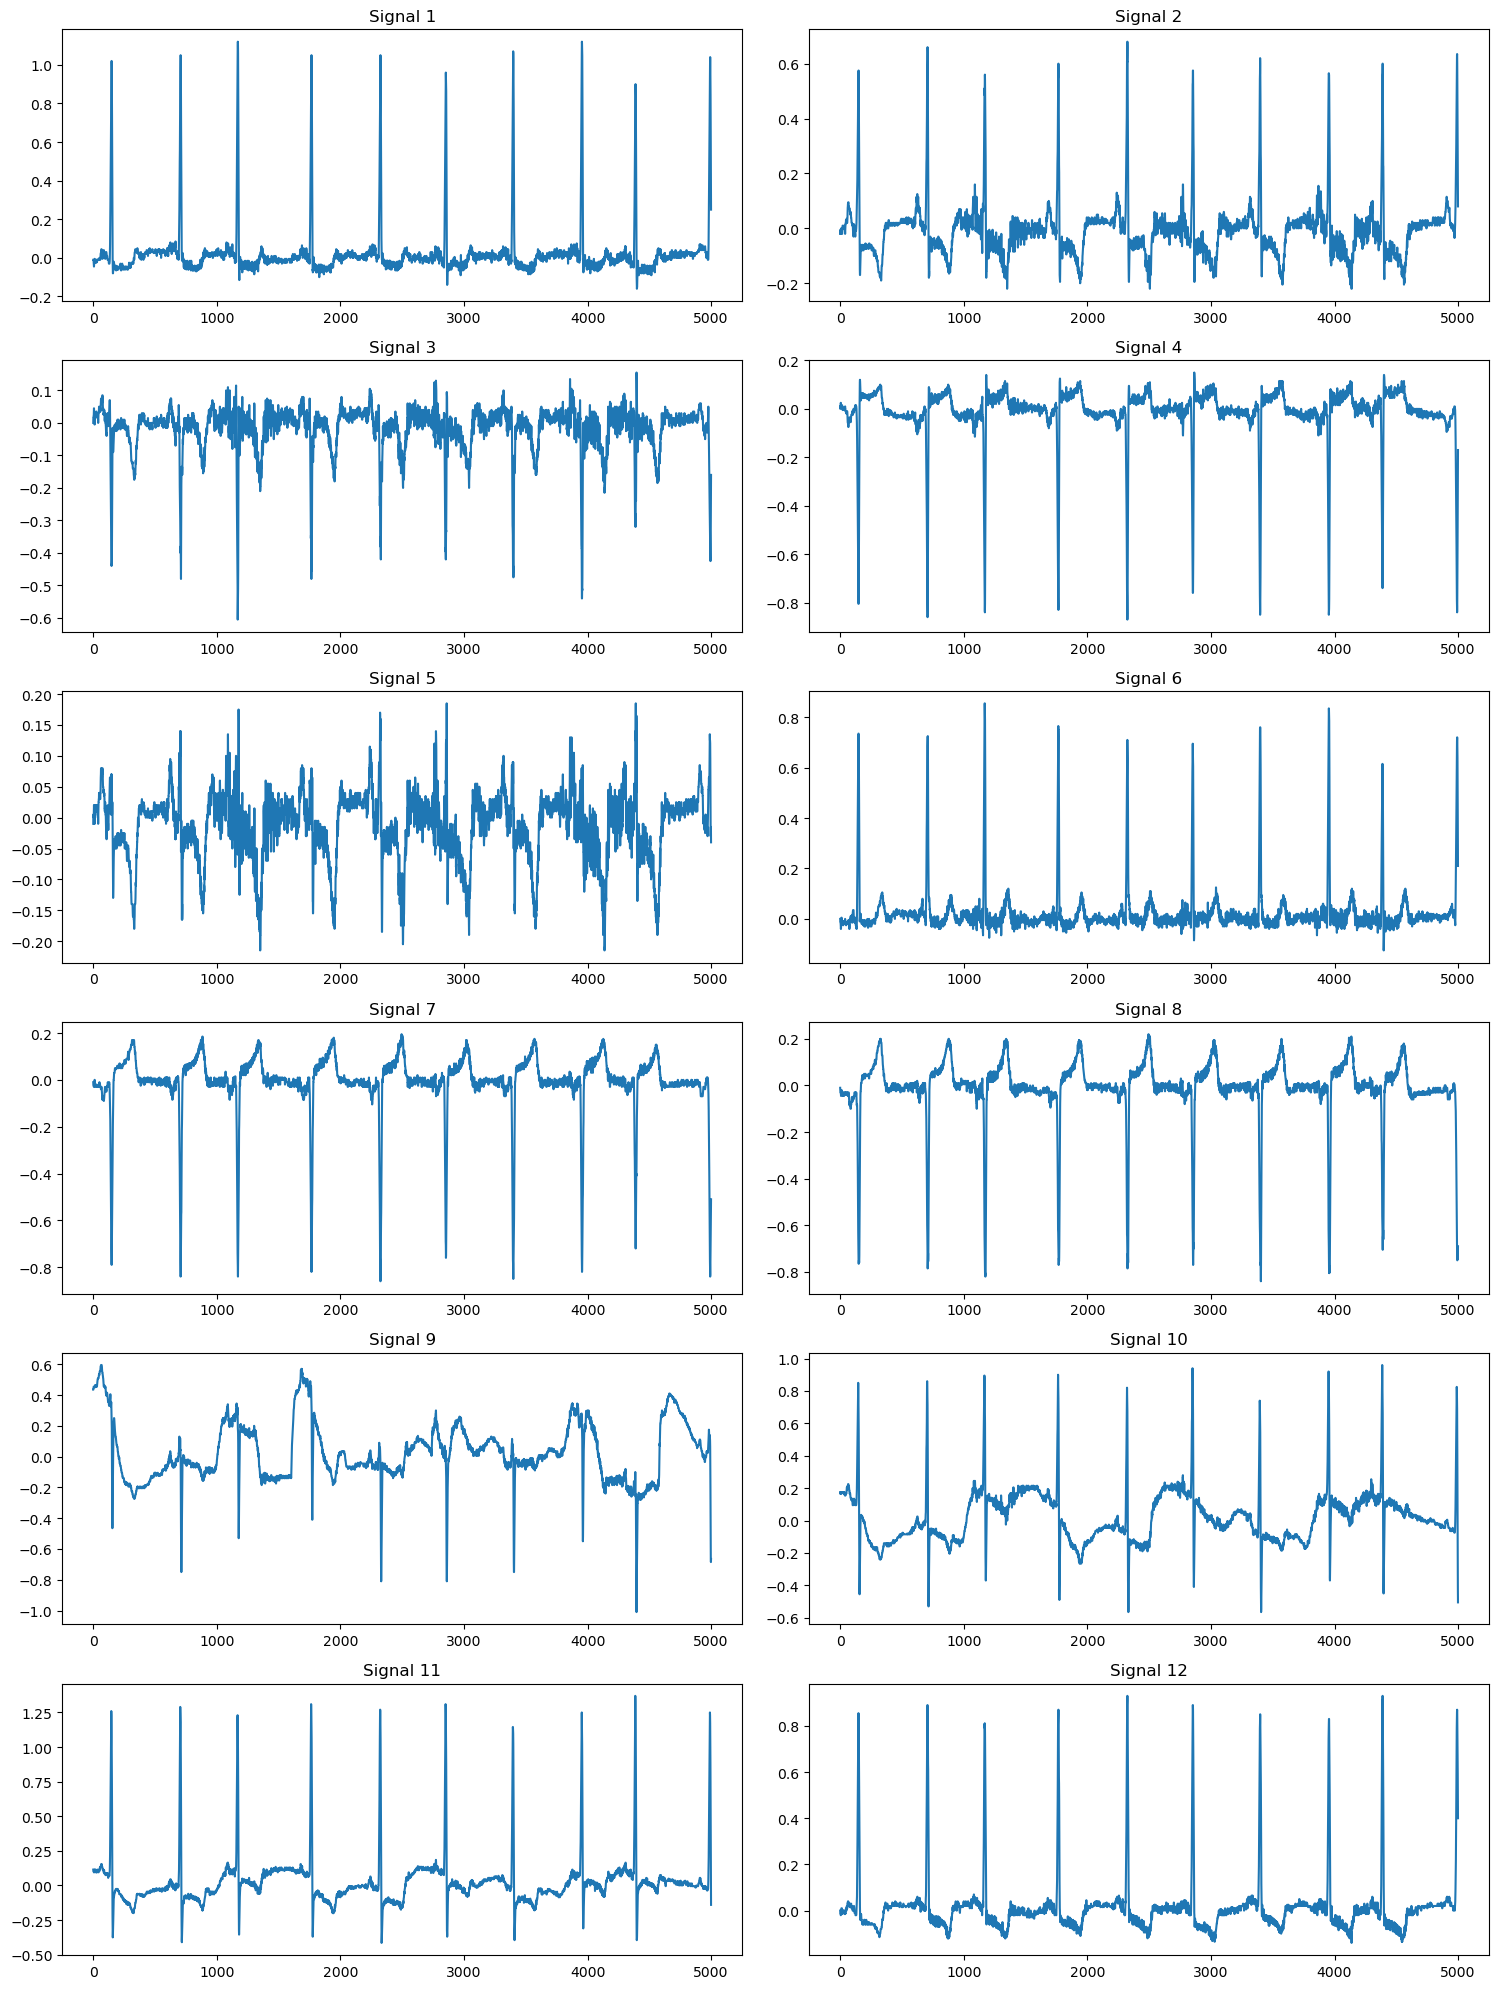

In [4]:
# For the first subject, plot all the ECG signals in two columns of six plots
first_subject = subject_infos_df.iloc[0]
record_path = FOLDER_PATH / first_subject['folder_name'] / first_subject['record_name']
record = wfdb.rdrecord(str(record_path))
num_signals = record.p_signal.shape[1]
fig, axs = plt.subplots(6, 2, figsize=(15, 20))
for i in range(num_signals):
    ax = axs[i // 2, i % 2]
    ax.plot(record.p_signal[:, i])
    ax.set_title(f'Signal {i+1}')
plt.tight_layout()
plt.show()

# Time Series Understanding

Given a time series, it is interesting to understand the behaviour of the it; to do so we can check for some particular informations:
- **Trends**
- **Seasonality**
- **Cyclicity**

## Noise removal

### Rolling window approach

The first idea to remove noise in the time series is to use a rolling window (with a defeault value of 5), and smooth the curve. 

In [5]:
# Remove noise in the time series by applying a rolling window average filter
def moving_average(signal, window_size=5):
    """
    Apply moving average filter to a numpy array signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input signal
    window_size : int
        Size of the moving average window
        
    Returns:
    --------
    pandas.Series
        Filtered signal with NaN at edges
    """
    # Convert to pandas Series for rolling window operations
    signal_series = pd.Series(signal)
    
    # Standardize: (x - mean) / std
    standardized = (signal_series - signal_series.mean()) / signal_series.std()
    
    # Apply rolling window average
    filtered = standardized.rolling(window=window_size, center=True).mean()
    
    return filtered

def moving_std(signal, window_size=5):
    """
    Apply moving standard deviation filter to a numpy array signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input signal
    window_size : int
        Size of the moving std window
        
    Returns:
    --------
    pandas.Series
        Filtered signal with NaN at edges
    """
    # Convert to pandas Series for rolling window operations
    signal_series = pd.Series(signal)
    
    # Standardize: (x - mean) / std
    standardized = (signal_series - signal_series.mean()) / signal_series.std()
    
    # Apply rolling window standard deviation
    filtered = standardized.rolling(window=window_size, center=True).std()
    
    return filtered


### Low/High-Pass and Band-Pass filters

Another option is to use *Low-Pass*, *High-Pass* and *Band-Pass* filters to remove the noise on ECG signals.
- **Low-Pass filter**: A Low-Pass filter (LPF) is a filter that passes signals with a frequency lower than a selected cutoff frequency and attenuates signals with frequencies higher than the cutoff frequency.
- **High-Pass filter**: A High-Pass filter (HPF) is an electronic filter that passes signals with a frequency higher than a certain cutoff frequency and attenuates signals with frequencies lower than the cutoff frequency.
- **Band-Pass filter**: A Band-Pass filter allows through components in a specified band of frequencies, called its passband but blocks components with frequencies above or below this band. This contrasts with a high-pass filter, which allows through components with frequencies above a specific frequency, and a low-pass filter, which allows through components with frequencies below a specific frequency.

In [6]:
def low_pass_filter(signal, fs, cutoff=30, order=5):
    """
    Apply a low-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def high_pass_filter(signal, fs, cutoff=0.5, order=5):
    """
    Apply a high-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='high', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def band_pass_filter(signal, fs, lowcut=0.5, highcut=30, order=5):
    """
    Apply a band-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    lowcut : float
        Low cutoff frequency of the filter
    highcut : float
        High cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequencies
    low = lowcut / nyquist
    high = highcut / nyquist

    # Get the filter coefficients
    b, a = butter(order, [low, high], btype='band')

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal


### Pan-Tompkins algorithm

In [7]:
def pt_algorithm(signal, fs):
    """
    Apply the Pan-Tompkins algorithm to detect R-peaks in ECG signals.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input ECG signal
    fs : float
        Sampling frequency
        
    Returns:
    --------
    r_peaks : numpy.ndarray
        Indices of detected R-peaks in the signal
    """
    # Step 1: Low-pass filter (0.5-30 Hz)
    lp_filtered = low_pass_filter(signal, fs, cutoff=30, order=5)

    hp_filtered = high_pass_filter(lp_filtered, fs, cutoff=0.5, order=5)
    
    # Step 2: Derivative filter
    derivative_signal = np.diff(hp_filtered)
    
    # Step 3: Squaring
    squared_signal = np.square(derivative_signal)
    
    # Step 4: Moving window integration
    window_size = int(0.150 * fs)  # 150 ms window
    integrated_signal = moving_average(squared_signal, window_size=window_size).fillna(0).values
    
    return integrated_signal

In [8]:
def QRSpeaks(signal, fs):
    """
    Detect QRS peaks (R-peaks) in Pan-Tompkins processed signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Integrated signal from Pan-Tompkins algorithm
    fs : float
        Sampling frequency
        
    Returns:
    --------
    peaks : numpy.ndarray
        Indices of detected R-peaks
    """
    # Use find_peaks from scipy.signal (already imported)
    peaks, _ = find_peaks(signal, height=np.mean(signal), distance=round(fs*0.200))
    return peaks

## Time series data quality

In [9]:
# For each subject, take lead II and V5 joined together in a single signal
subj_dict = {}
for subject_id, row in subject_infos_df.iterrows():
    record_name = row['record_name']
    data = timeseries_dict[record_name]
    signal = data['signal']
    fs = data['fs']
    num_samples = data['samples_per_channel']
    
    # Extract lead II (index 1) and V5 (index 4)
    lead_II = signal[1 * num_samples : 2 * num_samples]
    lead_V5 = signal[4 * num_samples : 5 * num_samples]
    
    subject_id = subject_infos_df.iloc[subject_id]['subject_id']
    subj_dict[subject_id] = {
        'II': lead_II,
        'V5': lead_V5,
        'fs': fs
    }

In [10]:
scaler = StandardScaler()
subject_id = list(subj_dict.keys())[0]
original_II_signal = subj_dict[subject_id]['II']
original_V5_signal = subj_dict[subject_id]['V5']
fs = subj_dict[subject_id]['fs']

scaled_II_signal = scaler.fit_transform(original_II_signal.reshape(-1, 1)).flatten()
scaled_V5_signal = scaler.fit_transform(original_V5_signal.reshape(-1, 1)).flatten()

### Noise cancellation approach 1: Using the rolling window to clean the time series

In [11]:
mavg_filtered_II = moving_average(scaled_II_signal, window_size=5).fillna(0).values
mavg_filtered_V5 = moving_average(scaled_V5_signal, window_size=5).fillna(0).values

### Noise cancellation approach 2: Using the Band-Pass filter to cancel the noise in the time series

In [12]:
bp_filtered_II = band_pass_filter(scaled_II_signal, fs, lowcut=0.5, highcut=30, order=5)
bp_filtered_V5 = band_pass_filter(scaled_V5_signal, fs, lowcut=0.5, highcut=30, order=5)

#### Comparison of the two methods

Lead II - Difference MA Filter - Mean: -0.0007, Std: 0.1081
Lead II - Difference BP Filter - Mean: 0.0152, Std: 0.2322
Lead V5 - Difference MA Filter - Mean: 0.0000, Std: 0.1821
Lead V5 - Difference BP Filter - Mean: 0.0184, Std: 0.3873


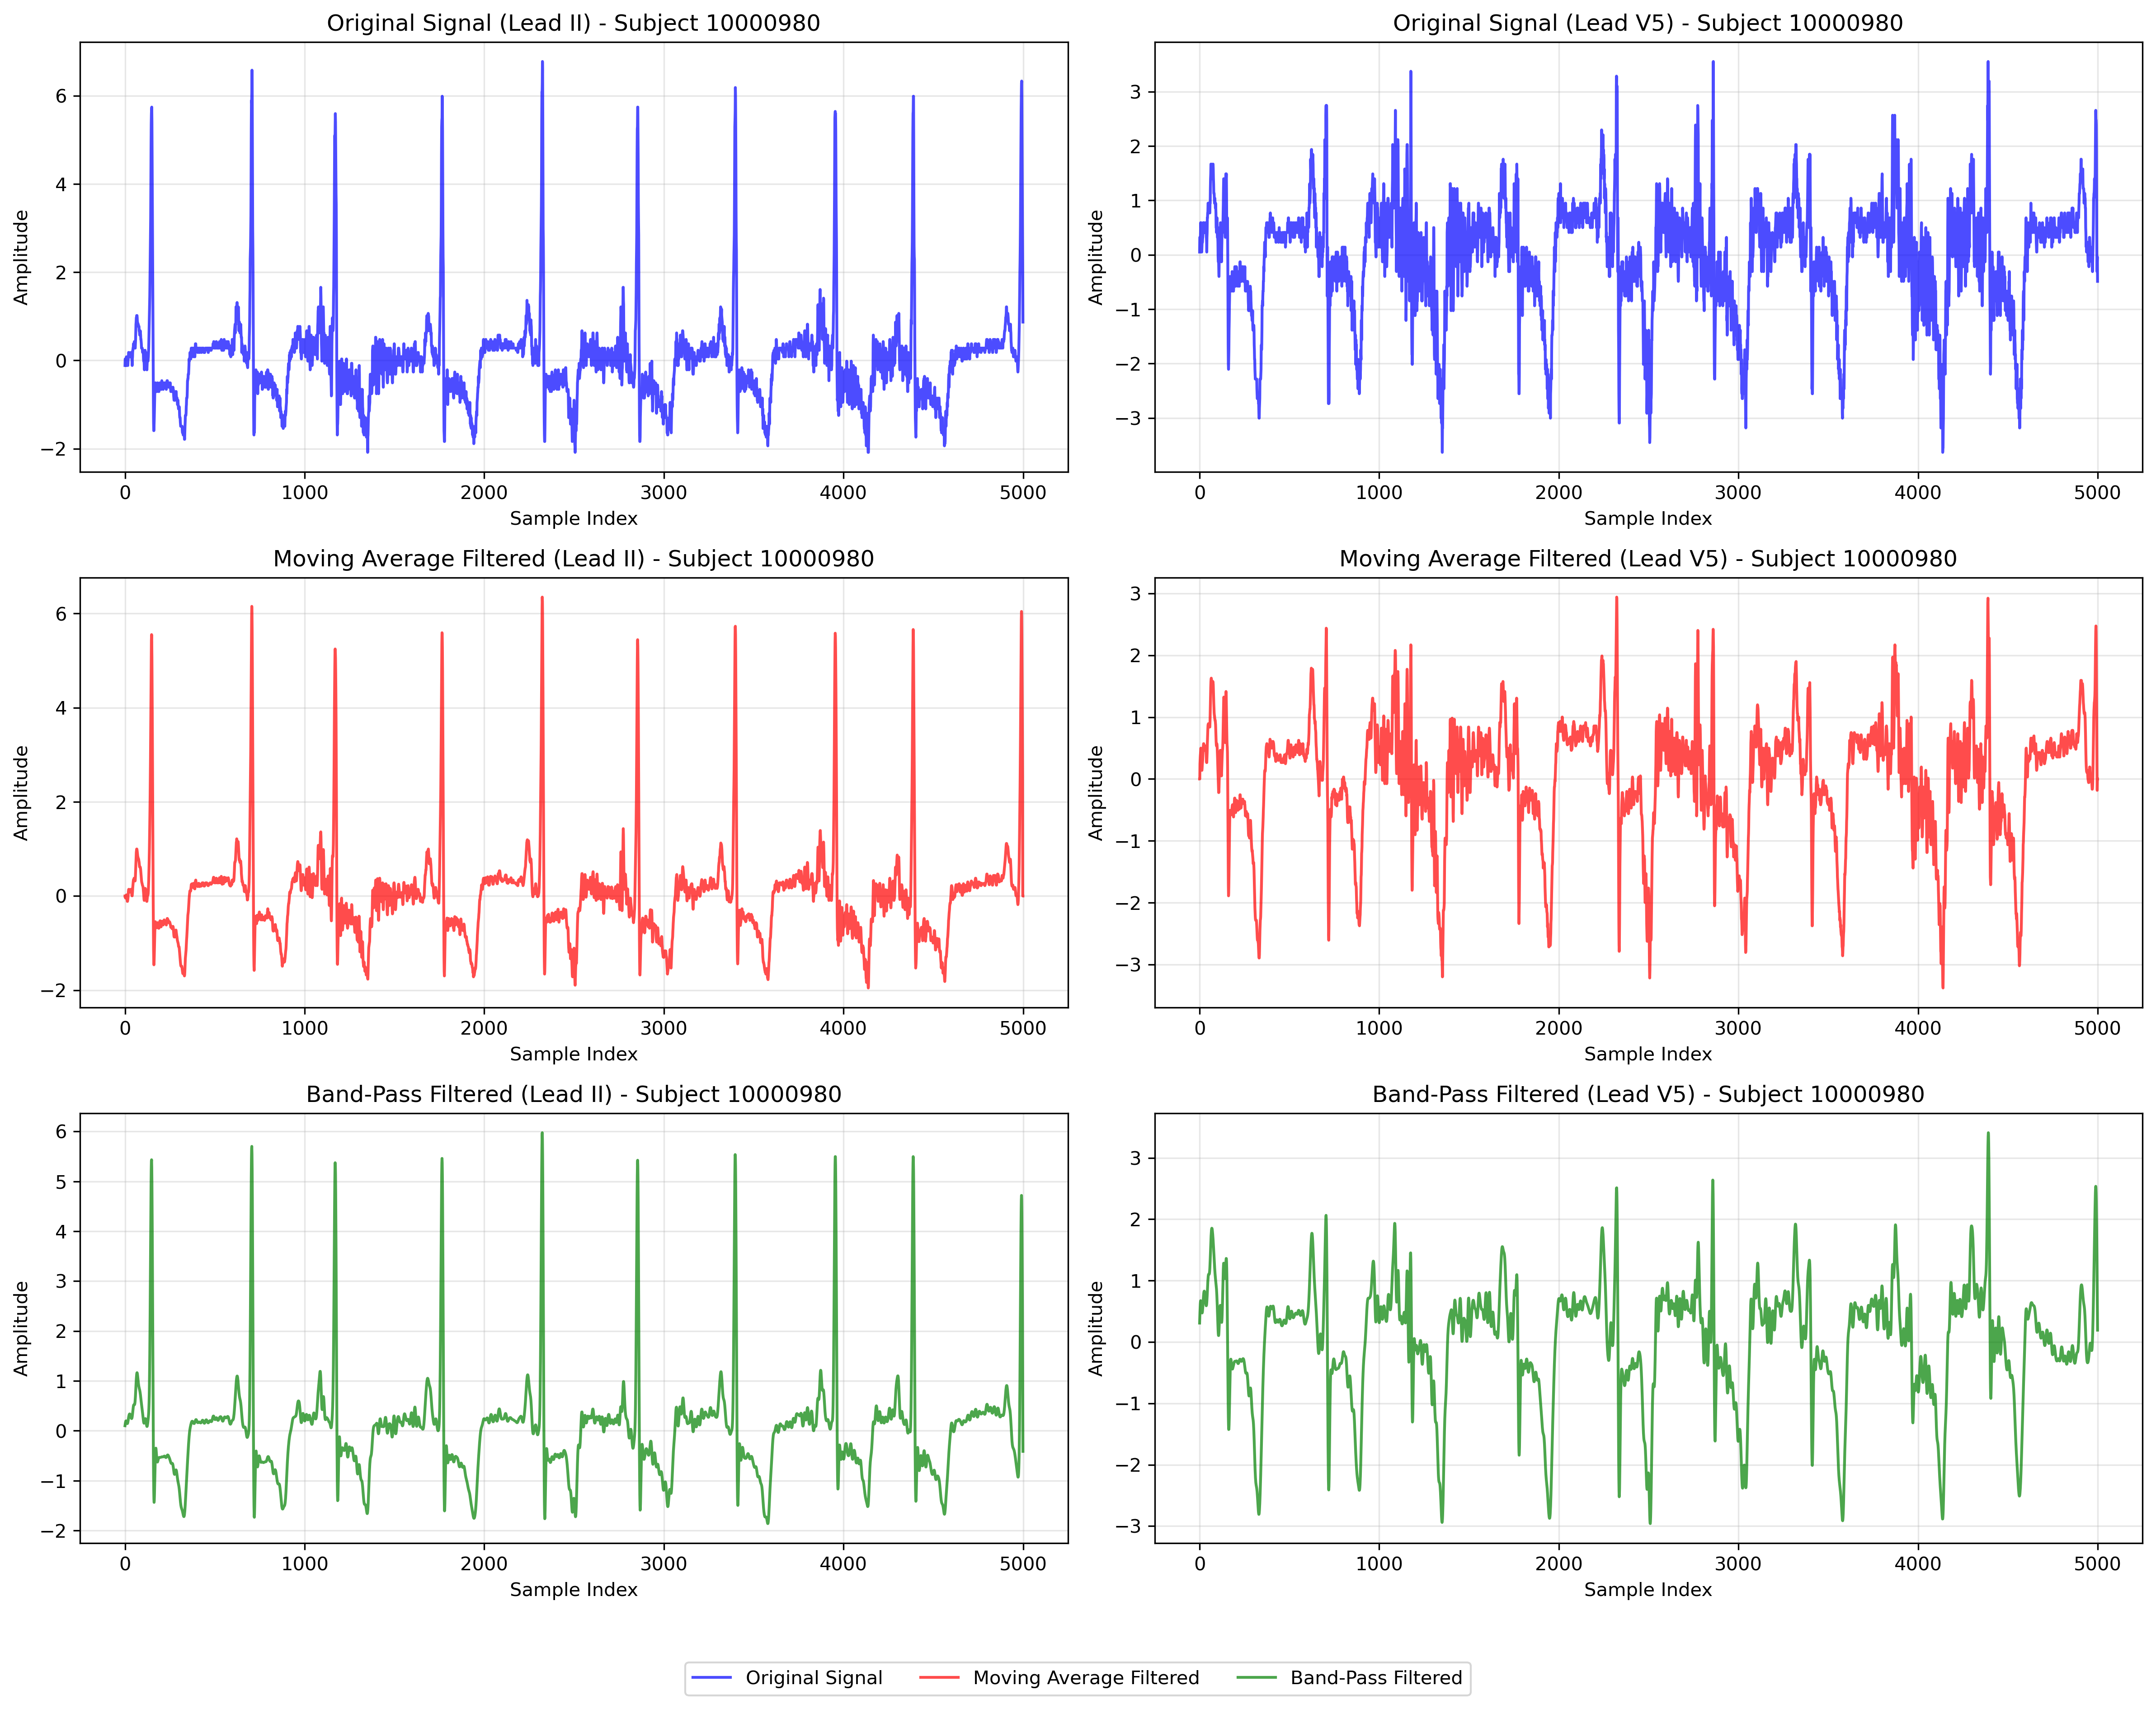

In [13]:
# Calculate the differences between the filtered and the original (for each lead separately)
diff_ma_II = mavg_filtered_II - scaled_II_signal
diff_ma_V5 = mavg_filtered_V5 - scaled_V5_signal
diff_bp_II = bp_filtered_II - scaled_II_signal
diff_bp_V5 = bp_filtered_V5 - scaled_V5_signal

print(f"Lead II - Difference MA Filter - Mean: {np.mean(diff_ma_II):.4f}, Std: {np.std(diff_ma_II):.4f}")
print(f"Lead II - Difference BP Filter - Mean: {np.mean(diff_bp_II):.4f}, Std: {np.std(diff_bp_II):.4f}")
print(f"Lead V5 - Difference MA Filter - Mean: {np.mean(diff_ma_V5):.4f}, Std: {np.std(diff_ma_V5):.4f}")
print(f"Lead V5 - Difference BP Filter - Mean: {np.mean(diff_bp_V5):.4f}, Std: {np.std(diff_bp_V5):.4f}")


fig, axes = plt.subplots(3, 2, figsize=(16, 12), dpi=300)

# Column 1: Lead II
# Plot 1: Original Signal - Lead II
axes[0, 0].plot(scaled_II_signal, label='Original Signal', color='blue', alpha=0.7)
axes[0, 0].set_title(f'Original Signal (Lead II) - Subject {subject_id}')
axes[0, 0].set_xlabel('Sample Index')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Moving Average Filtered - Lead II
axes[1, 0].plot(mavg_filtered_II, label='Moving Average Filtered', color='red', alpha=0.7)
axes[1, 0].set_title(f'Moving Average Filtered (Lead II) - Subject {subject_id}')
axes[1, 0].set_xlabel('Sample Index')
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].grid(True, alpha=0.3)

# Plot 3: Band-Pass Filtered - Lead II
axes[2, 0].plot(bp_filtered_II, label='Band-Pass Filtered', color='green', alpha=0.7)
axes[2, 0].set_title(f'Band-Pass Filtered (Lead II) - Subject {subject_id}')
axes[2, 0].set_xlabel('Sample Index')
axes[2, 0].set_ylabel('Amplitude')
axes[2, 0].grid(True, alpha=0.3)

# Column 2: Lead V5
# Plot 1: Original Signal - Lead V5
axes[0, 1].plot(scaled_V5_signal, label='Original Signal', color='blue', alpha=0.7)
axes[0, 1].set_title(f'Original Signal (Lead V5) - Subject {subject_id}')
axes[0, 1].set_xlabel('Sample Index')
axes[0, 1].set_ylabel('Amplitude')
axes[0, 1].grid(True, alpha=0.3)

# Plot 2: Moving Average Filtered - Lead V5
axes[1, 1].plot(mavg_filtered_V5, label='Moving Average Filtered', color='red', alpha=0.7)
axes[1, 1].set_title(f'Moving Average Filtered (Lead V5) - Subject {subject_id}')
axes[1, 1].set_xlabel('Sample Index')
axes[1, 1].set_ylabel('Amplitude')
axes[1, 1].grid(True, alpha=0.3)

# Plot 3: Band-Pass Filtered - Lead V5
axes[2, 1].plot(bp_filtered_V5, label='Band-Pass Filtered', color='green', alpha=0.7)
axes[2, 1].set_title(f'Band-Pass Filtered (Lead V5) - Subject {subject_id}')
axes[2, 1].set_xlabel('Sample Index')
axes[2, 1].set_ylabel('Amplitude')
axes[2, 1].grid(True, alpha=0.3)

plt.tight_layout()
handles = [axes[0, 0].get_lines()[0], axes[1, 0].get_lines()[0], axes[2, 0].get_lines()[0]]
labels = ['Original Signal', 'Moving Average Filtered', 'Band-Pass Filtered']
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=True)
plt.show()

In [14]:
# For all the subjects, use the band-pass filter and save the filtered signals
for subject_id, data in subj_dict.items():
    fs = data['fs']
    lead_II = data['II']
    lead_V5 = data['V5']
    
    # Scale the signals
    scaled_II_signal = scaler.fit_transform(lead_II.reshape(-1, 1)).flatten()
    scaled_V5_signal = scaler.fit_transform(lead_V5.reshape(-1, 1)).flatten()
    
    # Apply band-pass filter
    bp_filtered_II = band_pass_filter(scaled_II_signal, fs, lowcut=0.5, highcut=30, order=5)
    bp_filtered_V5 = band_pass_filter(scaled_V5_signal, fs, lowcut=0.5, highcut=30, order=5)
    
    # Update the dictionary with filtered signals
    subj_dict[subject_id]['bp_filtered_II'] = bp_filtered_II
    subj_dict[subject_id]['bp_filtered_V5'] = bp_filtered_V5

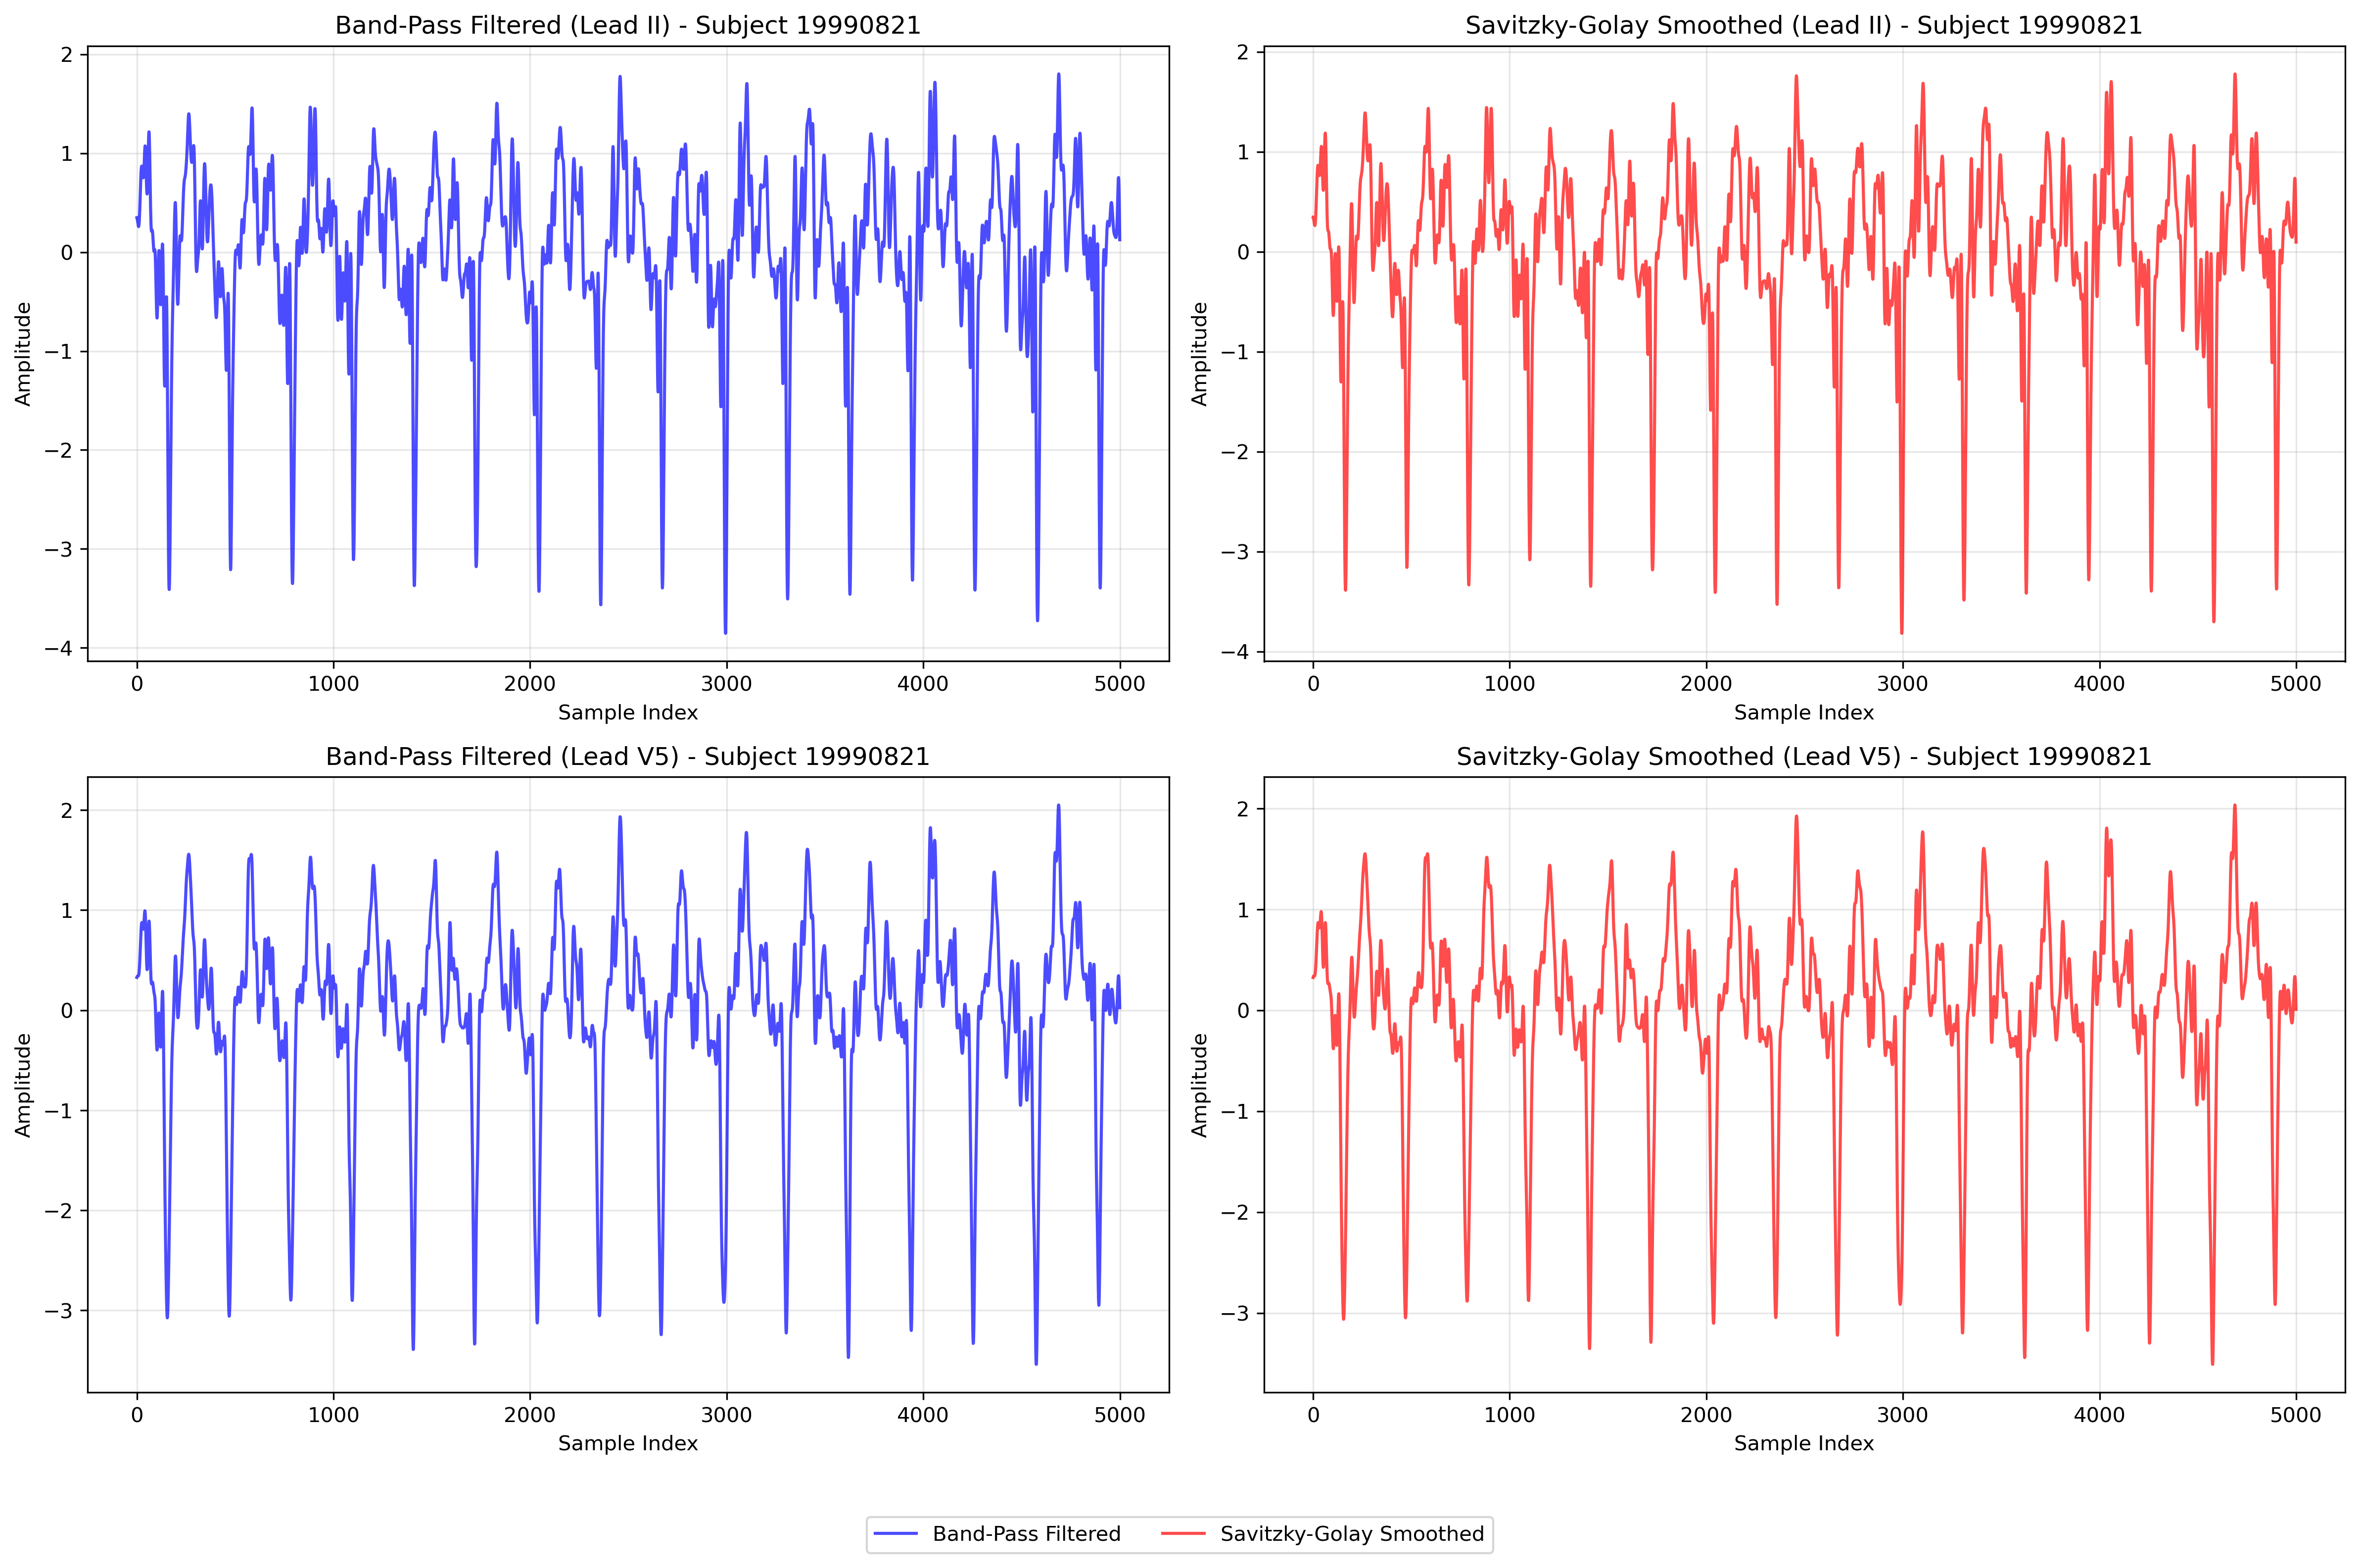

Lead II - Difference (Smoothed - BP Filtered) - Mean: 0.0000, Std: 0.0184
Lead V5 - Difference (Smoothed - BP Filtered) - Mean: 0.0000, Std: 0.0104


In [15]:
from scipy.signal import savgol_filter

def smooth_cardiac_signal(signal, window_size=15, poly_order=3):
    """
    Smoothes the signal while preserving R-peak height.
    window_size: Must be odd. At 500Hz, 15-31 is usually good.
    poly_order: 2 or 3 is typical for cardiac data.
    """
    return savgol_filter(signal, window_size, poly_order)

# Apply for the first subject and plot one under the other
smoothed_II = smooth_cardiac_signal(bp_filtered_II, window_size=15, poly_order=3)
smoothed_V5 = smooth_cardiac_signal(bp_filtered_V5, window_size=15, poly_order=3)

fig, axes = plt.subplots(2, 2, figsize=(16, 10), dpi=300)

# Row 1: Lead II
# Band-Pass Filtered Lead II
axes[0, 0].plot(bp_filtered_II, label='Band-Pass Filtered', color='blue', alpha=0.7)
axes[0, 0].set_title(f'Band-Pass Filtered (Lead II) - Subject {subject_id}')
axes[0, 0].set_xlabel('Sample Index')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].grid(True, alpha=0.3)

# Smoothed Lead II
axes[0, 1].plot(smoothed_II, label='Savitzky-Golay Smoothed', color='red', alpha=0.7)
axes[0, 1].set_title(f'Savitzky-Golay Smoothed (Lead II) - Subject {subject_id}')
axes[0, 1].set_xlabel('Sample Index')
axes[0, 1].set_ylabel('Amplitude')
axes[0, 1].grid(True, alpha=0.3)

# Row 2: Lead V5
# Band-Pass Filtered Lead V5
axes[1, 0].plot(bp_filtered_V5, label='Band-Pass Filtered', color='blue', alpha=0.7)
axes[1, 0].set_title(f'Band-Pass Filtered (Lead V5) - Subject {subject_id}')
axes[1, 0].set_xlabel('Sample Index')
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].grid(True, alpha=0.3)

# Smoothed Lead V5
axes[1, 1].plot(smoothed_V5, label='Savitzky-Golay Smoothed', color='red', alpha=0.7)
axes[1, 1].set_title(f'Savitzky-Golay Smoothed (Lead V5) - Subject {subject_id}')
axes[1, 1].set_xlabel('Sample Index')
axes[1, 1].set_ylabel('Amplitude')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
handles = [axes[0, 0].get_lines()[0], axes[0, 1].get_lines()[0]]
labels = ['Band-Pass Filtered', 'Savitzky-Golay Smoothed']
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=True)
plt.show()

# Print the difference between the smoothed and band-pass filtered signals
diff_II = smoothed_II - bp_filtered_II
diff_V5 = smoothed_V5 - bp_filtered_V5
print(f"Lead II - Difference (Smoothed - BP Filtered) - Mean: {np.mean(diff_II):.4f}, Std: {np.std(diff_II):.4f}")
print(f"Lead V5 - Difference (Smoothed - BP Filtered) - Mean: {np.mean(diff_V5):.4f}, Std: {np.std(diff_V5):.4f}")

In [16]:
# For each subject, apply the savitzky-golay filter and save the smoothed signals
for subject_id, data in subj_dict.items():
    bp_filtered_II = data['bp_filtered_II']
    bp_filtered_V5 = data['bp_filtered_V5']
    
    # Apply Savitzky-Golay smoothing
    smoothed_II = smooth_cardiac_signal(bp_filtered_II, window_size=15, poly_order=3)
    smoothed_V5 = smooth_cardiac_signal(bp_filtered_V5, window_size=15, poly_order=3)
    
    # Update the dictionary with smoothed signals
    subj_dict[subject_id]['smoothed_II'] = smoothed_II
    subj_dict[subject_id]['smoothed_V5'] = smoothed_V5

#### Peak detection using Pan-Tompkins algorithm

In [17]:
# Run the Pan-Tompkins algorithm on the band-pass filtered signals to detect R-peaks
for subject_id, data in subj_dict.items():
    fs = data['fs']
    bp_filtered_II = data['bp_filtered_II']
    bp_filtered_V5 = data['bp_filtered_V5']
    
    # Apply Pan-Tompkins algorithm
    pt_processed_II = pt_algorithm(bp_filtered_II, fs)
    pt_processed_V5 = pt_algorithm(bp_filtered_V5, fs)
    
    # Detect R-peaks
    r_peaks_II = QRSpeaks(pt_processed_II, fs)
    r_peaks_V5 = QRSpeaks(pt_processed_V5, fs)
    
    # Save R-peaks indices to the dictionary
    subj_dict[subject_id]['r_peaks_II'] = r_peaks_II
    subj_dict[subject_id]['r_peaks_V5'] = r_peaks_V5

In [18]:
# Get the seasonal period using the Pan-Tompkins detected R-peaks
for subject_id, data in subj_dict.items():
    fs = data['fs']
    r_peaks_II = data['r_peaks_II']
    
    # Calculate RR intervals in samples
    rr_intervals_samples = np.diff(r_peaks_II)
    
    # Convert RR intervals to seconds
    rr_intervals_seconds = rr_intervals_samples / fs
    
    # Calculate average heart rate (beats per minute)
    avg_rr_interval = np.mean(rr_intervals_seconds)
    avg_heart_rate_bpm = 60 / avg_rr_interval if avg_rr_interval > 0 else 0
    
    # Calculate seasonal period in samples
    seasonal_period_samples = int(fs * avg_rr_interval)
    
    # Save seasonal period and average heart rate to the dictionary
    subj_dict[subject_id]['seasonal_period_samples'] = seasonal_period_samples
    subj_dict[subject_id]['avg_heart_rate_bpm'] = avg_heart_rate_bpm

## Extracting features

In [19]:
from scipy import stats

def extract_basic_features(signal, fs):
    """
    Extract basic statistical features from the ECG signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input ECG signal
    fs : float
        Sampling frequency
        
    Returns:
    --------
    features : dict
        Dictionary containing extracted statistical features
    """
    features = {
        'avg': np.mean(signal),
        'std': np.std(signal),
        'var': np.var(signal),
        'med': np.median(signal),
        '10p': np.percentile(signal, 10),
        '25p': np.percentile(signal, 25),
        '50p': np.percentile(signal, 50),
        '75p': np.percentile(signal, 75),
        '90p': np.percentile(signal, 90),
        'iqr': np.percentile(signal, 75) - np.percentile(signal, 25),
        'cov': 1.0 * np.mean(signal) / np.std(signal) if np.std(signal) != 0 else 0,
        'skw': stats.skew(signal),
        'kur': stats.kurtosis(signal)
    }

    return features

In [20]:
def extract_time_domain_hrv(r_peaks, fs):
    # Convert peak indices to time intervals in milliseconds
    rr_intervals = np.diff(r_peaks) / fs * 1000 
    
    # SDNN: Standard Deviation of NN intervals
    sdnn = np.std(rr_intervals)
    
    # RMSSD: Root Mean Square of Successive Differences
    diff_rr = np.diff(rr_intervals)
    rmssd = np.sqrt(np.mean(np.square(diff_rr)))
    
    # pNN50: Percentage of successive intervals differing by > 50ms
    nn50 = np.sum(np.abs(diff_rr) > 50)
    pnn50 = (nn50 / len(diff_rr)) * 100
    return {
        'SDNN': sdnn,
        'RMSSD': rmssd,
        'pNN50': pnn50
    }

In [21]:
def extract_detailed_morphology(signal, r_peaks, fs, window_ms=600):
    """
    Extracts the average heartbeat template and key morphological metrics.
    """
    # Convert window from milliseconds to samples
    window_samples = int((window_ms / 1000) * fs)
    half_win = window_samples // 2
    
    heartbeats = []
    for r in r_peaks:
        # Ensure we don't go out of signal bounds
        if r > half_win and r < len(signal) - half_win:
            segment = signal[r - half_win : r + half_win]
            # Baseline correction: subtract the mean of the segment
            segment = segment - np.mean(segment)
            heartbeats.append(segment)
            
    if not heartbeats:
        return None

    # Calculate the Template (Ensemble Average)
    template = np.mean(heartbeats, axis=0)
    
    # Feature Extraction from Template
    # 1. R-Peak Amplitude (max value in the center)
    r_amplitude = np.max(template)
    
    # 2. QRS Duration (rough estimate by width at half-max of the R-peak)
    # Finding points where signal is > 50% of peak height
    qrs_indices = np.where(template > (r_amplitude * 0.5))[0]
    qrs_duration_ms = (len(qrs_indices) / fs) * 1000
    
    # 3. Kurtosis of the Template (measures "peakiness")
    from scipy.stats import kurtosis
    template_kurtosis = kurtosis(template)

    return {
        "template": template,
        "r_amplitude": r_amplitude,
        "qrs_duration_ms": qrs_duration_ms,
        "template_kurtosis": template_kurtosis
    }

In [22]:
# Create a data with all the features for each subject
features_list = []
for subject_id, data in subj_dict.items():
    fs = data['fs']
    r_peaks_II = data['r_peaks_II']
    r_peaks_V5 = data['r_peaks_V5']
    smoothed_II = data['smoothed_II']
    smoothed_V5 = data['smoothed_V5']

    # Basic Statistical Features
    basic_II = extract_basic_features(smoothed_II, fs)
    basic_V5 = extract_basic_features(smoothed_V5, fs)
    
    # Time-Domain HRV Features
    hrv_II = extract_time_domain_hrv(r_peaks_II, fs)
    hrv_V5 = extract_time_domain_hrv(r_peaks_V5, fs)
    
    # Morphological Features
    morph_II = extract_detailed_morphology(smoothed_II, r_peaks_II, fs)
    morph_V5 = extract_detailed_morphology(smoothed_V5, r_peaks_V5, fs)


    
    # Combine all features into a single dictionary
    features = {
        'subject_id': subject_id,
        #Cleaned and smoothed signals
        'smoothed_II': smoothed_II,
        'smoothed_V5': smoothed_V5,
        # Basic Features Lead II
        #**{f'II_basic_{k}': v for k, v in basic_II.items()},
        # Basic Features Lead V5
        #**{f'V5_basic_{k}': v for k, v in basic_V5.items()},
        # HRV Features Lead II
        **{f'II_hrv_{k}': v for k, v in hrv_II.items()},
        # HRV Features Lead V5
        **{f'V5_hrv_{k}': v for k, v in hrv_V5.items()},
        # Morphological Features Lead II
        'II_r_amplitude': morph_II['r_amplitude'] if morph_II else np.nan,
        'II_qrs_duration_ms': morph_II['qrs_duration_ms'] if morph_II else np.nan,
        'II_template_kurtosis': morph_II['template_kurtosis'] if morph_II else np.nan,
        # Morphological Features Lead V5
        'V5_r_amplitude': morph_V5['r_amplitude'] if morph_V5 else np.nan,
        'V5_qrs_duration_ms': morph_V5['qrs_duration_ms'] if morph_V5 else np.nan,
        'V5_template_kurtosis': morph_V5['template_kurtosis'] if morph_V5 else np.nan,

    }

    features_list.append(features)
features_df = pd.DataFrame(features_list)
features_df

,subject_id,smoothed_II,smoothed_V5,II_hrv_SDNN,II_hrv_RMSSD,II_hrv_pNN50,V5_hrv_SDNN,V5_hrv_RMSSD,V5_hrv_pNN50,II_r_amplitude,II_qrs_duration_ms,II_template_kurtosis,V5_r_amplitude,V5_qrs_duration_ms,V5_template_kurtosis
0,10000980,"[0.09426918915363115, 0.13102694114089175, 0.1...","[0.28758889120771625, 0.4126170061392071, 0.50...",92.649879,163.676510,62.500000,195.175300,349.697012,100.000000,2.757637,36.0,1.133009,0.509771,134.0,0.350976
1,10004457,"[-0.17110649065693853, -0.17573695129669084, -...","[-0.15040324378660797, -0.15768485004283112, -...",11.889465,18.853824,0.000000,13.793114,23.658684,0.000000,4.568426,28.0,13.348455,4.383817,30.0,12.986464
2,10007058,"[0.027518288072748195, 0.035552667670175564, 0...","[0.11510745200213084, 0.11465134743345835, 0.1...",25.785439,31.717503,12.500000,24.557315,31.024184,12.500000,3.102317,18.0,9.908614,2.901136,16.0,7.292927
3,10018684,"[-0.11601419637614092, -0.17089621947159478, -...","[-0.29042235634667407, -0.36444653058491594, -...",20.240904,32.967516,9.523810,31.307724,55.583485,19.047619,0.563484,160.0,3.849309,0.642534,156.0,2.917021
4,10044096,"[-0.051859495094370496, -0.06996940537503653, ...","[0.05536666846859816, 0.05225165892558095, 0.0...",253.814358,477.263030,50.000000,254.275441,479.521637,50.000000,2.237156,56.0,1.416101,2.049369,52.0,1.653952
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1781,19969326,"[0.13251892048399905, 0.05307477665610459, -0....","[-0.02736118679789899, -0.09333675876131863, -...",92.993763,129.393728,73.684211,96.036660,135.883077,73.684211,2.430076,32.0,3.617473,2.470692,32.0,3.773723
1782,19969991,"[0.25272275112600523, 0.2679980919617599, 0.27...","[0.34936212853062243, 0.33994566428317086, 0.3...",19.355849,30.761757,7.142857,120.591705,154.032031,46.666667,1.151457,136.0,0.501665,1.314487,102.0,0.745992
1783,19970101,"[-0.035485507247157884, -0.02030367311639871, ...","[0.058713975737326465, 0.05291771507833401, 0....",165.098672,209.307282,76.923077,58.374834,95.071903,58.333333,1.510161,106.0,0.158558,1.373400,90.0,0.162454
1784,19985259,"[-0.12257340203449632, -0.15569189154435265, -...","[-0.13921092781501967, -0.1723452757561733, -0...",151.014202,284.852242,50.000000,153.630662,293.168893,40.000000,2.982726,26.0,8.115518,3.579465,28.0,7.850369


In [23]:
hd_df = pd.read_csv('../../data/processed/hd.csv')

features_df['subject_id'] = features_df['subject_id'].astype(int)
full_df = pd.merge(features_df, hd_df, on='subject_id', how='inner')

full_df.to_csv('../../data/processed/time_series_features.csv', index=False)
full_df

,subject_id,smoothed_II,smoothed_V5,II_hrv_SDNN,II_hrv_RMSSD,II_hrv_pNN50,V5_hrv_SDNN,V5_hrv_RMSSD,V5_hrv_pNN50,II_r_amplitude,II_qrs_duration_ms,II_template_kurtosis,V5_r_amplitude,V5_qrs_duration_ms,V5_template_kurtosis,hadm_id,icd_code,long_title,gender,age
0,10000980,"[0.09426918915363115, 0.13102694114089175, 0.1...","[0.28758889120771625, 0.4126170061392071, 0.50...",92.649879,163.676510,62.500000,195.175300,349.697012,100.000000,2.757637,36.0,1.133009,0.509771,134.0,0.350976,29654838,I50,Heart failure,F,75.0
1,10000980,"[0.09426918915363115, 0.13102694114089175, 0.1...","[0.28758889120771625, 0.4126170061392071, 0.50...",92.649879,163.676510,62.500000,195.175300,349.697012,100.000000,2.757637,36.0,1.133009,0.509771,134.0,0.350976,26913865,I21,Acute myocardial infarction,F,75.0
2,10004457,"[-0.17110649065693853, -0.17573695129669084, -...","[-0.15040324378660797, -0.15768485004283112, -...",11.889465,18.853824,0.000000,13.793114,23.658684,0.000000,4.568426,28.0,13.348455,4.383817,30.0,12.986464,28723315,I35,Nonrheumatic aortic valve disorders,M,66.0
3,10007058,"[0.027518288072748195, 0.035552667670175564, 0...","[0.11510745200213084, 0.11465134743345835, 0.1...",25.785439,31.717503,12.500000,24.557315,31.024184,12.500000,3.102317,18.0,9.908614,2.901136,16.0,7.292927,22954658,I21,Acute myocardial infarction,M,48.0
4,10018684,"[-0.11601419637614092, -0.17089621947159478, -...","[-0.29042235634667407, -0.36444653058491594, -...",20.240904,32.967516,9.523810,31.307724,55.583485,19.047619,0.563484,160.0,3.849309,0.642534,156.0,2.917021,26649049,I48,Atrial fibrillation and flutter,M,48.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1271,19969326,"[0.13251892048399905, 0.05307477665610459, -0....","[-0.02736118679789899, -0.09333675876131863, -...",92.993763,129.393728,73.684211,96.036660,135.883077,73.684211,2.430076,32.0,3.617473,2.470692,32.0,3.773723,20407284,I48,Atrial fibrillation and flutter,F,71.0
1272,19969991,"[0.25272275112600523, 0.2679980919617599, 0.27...","[0.34936212853062243, 0.33994566428317086, 0.3...",19.355849,30.761757,7.142857,120.591705,154.032031,46.666667,1.151457,136.0,0.501665,1.314487,102.0,0.745992,22950880,I48,Atrial fibrillation and flutter,F,62.0
1273,19970101,"[-0.035485507247157884, -0.02030367311639871, ...","[0.058713975737326465, 0.05291771507833401, 0....",165.098672,209.307282,76.923077,58.374834,95.071903,58.333333,1.510161,106.0,0.158558,1.373400,90.0,0.162454,28958051,I21,Acute myocardial infarction,M,87.0
1274,19985259,"[-0.12257340203449632, -0.15569189154435265, -...","[-0.13921092781501967, -0.1723452757561733, -0...",151.014202,284.852242,50.000000,153.630662,293.168893,40.000000,2.982726,26.0,8.115518,3.579465,28.0,7.850369,23988340,I47,Paroxysmal tachycardia,M,70.0
